# 📘 VariableSelector + Preprocessor + ResidualAnalyzer 튜토리얼 (6개 케이스 + 해석 주석)

이 노트북은 공개 데이터셋을 활용하여 **변수 선택 + 전처리 + 잔차 분석** 과정을 보여줍니다.  
모든 데이터셋을 **Train/Test (8:2)** 로 분할한 후, 각 케이스마다 다른 스케일러를 적용합니다.

---

## 📌 케이스별 조건
1. **Case 1 (수치형→수치형)** : diabetes 데이터 → Forward, `StandardScaler`
2. **Case 2 (수치형→이항)** : breast_cancer 데이터 → Backward, `MinMaxScaler`
3. **Case 3 (수치형→3범주)** : wine 데이터 → Stepwise, `RobustScaler`
4. **Case 4 (혼합→수치형)** : tips 데이터 → Forward, `스케일러 없음`
5. **Case 5 (혼합→이항)** : titanic 데이터 → Backward, `StandardScaler`
6. **Case 6 (혼합→3범주)** : iris 데이터(+가공) → Stepwise, `MinMaxScaler`

---

각 케이스에서 수행되는 절차:
1. 데이터 로드 및 Train/Test 분할 (8:2)
2. Preprocessor 전처리 (결측치 처리 + 스케일링 + 원핫 + y 인코딩)
3. VariableSelector 실행
4. 선택된 변수, 계수표(coef_table) 출력
5. AIC 변화 그래프
6. ResidualAnalyzer 플롯
7. Train/Test 성능 비교
8. **결과 해석 예시 (한국어 주석)**

---


## 📊 잔차 플롯 해석 가이드

- **Residuals vs Fitted**: 패턴 없이 랜덤 분포 → 선형성, 등분산성 만족. 곡선 → 비선형, 깔때기 모양 → 이분산성.  
- **Histogram of Residuals**: 정규분포 모양 → 정규성 만족. 치우침이나 꼬리 두꺼움 → 위반 가능성.  
- **Q-Q Plot**: 점들이 45도 직선 근처 → 정규성 만족. 꼬리 벗어남 → 극단치/분포 왜곡.  
- **Scale-Location Plot**: 퍼짐이 일정 → 등분산성. 퍼짐이 점점 커짐 → 이분산성.  
- **Residuals vs Leverage (Cook’s distance)**: 영향력이 큰 점 식별. Cook’s 거리 기준선을 벗어나면 주의 필요.  

In [2]:
from eda_manager.analyze.data_analyze.preprocess import Preprocessor
from eda_manager.analyze.data_analyze.regression import VariableSelector
from eda_manager.analyze.data_analyze.residual import ResidualAnalyzer
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import seaborn as sns
import pandas as pd

In [3]:
%matplotlib inline

## Case 1: 수치형→수치형 (diabetes, Forward, StandardScaler)

In [3]:
from sklearn.datasets import load_diabetes
from sklearn.metrics import mean_squared_error, r2_score
import statsmodels.api as sm

# 데이터 준비
data = load_diabetes(as_frame=True)
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 전처리
prep = Preprocessor(num_cols=X.columns.tolist(), cat_cols=None, scaler="standard", impute="median")
X_train_proc, y_train_enc = prep.fit_transform(X_train, y_train)
X_test_proc, y_test_enc = prep.transform(X_test, y_test)

# 변수 선택
sel = VariableSelector(X_train_proc, y_train_enc, method="forward", model_type="auto")
res = sel.select()

# 테스트셋 평가
X_test_sel = sm.add_constant(X_test_proc[res["variables"]])
model = sel.final_fit_
y_pred_test = model.predict(X_test_sel)

# 👉 해석 가이드
# - Forward 방식으로 변수를 하나씩 추가하면서 AIC가 개선되는 과정을 확인합니다.
# - coef_table에서 계수가 큰 변수는 종속변수(당뇨 지표)에 영향을 많이 주는 설명변수임을 의미합니다.
# - ResidualAnalyzer 플롯에서 잔차가 무작위로 분포하면 선형 회귀의 가정이 잘 충족된 것입니다.
# - Test RMSE와 R²를 통해 예측력이 어느 정도인지 확인할 수 있습니다.

# 📌 해석 예시 (Case 1)
# - Residual vs Fitted: 점들이 무작위로 흩어져 있으면 선형성이 잘 맞음.
#   곡선 패턴이 보이면 비선형 변수 추가 고려 필요.
# - Histogram, Q-Q: 잔차가 정규분포 형태 → 가정 충족.
#   치우침이 있으면 변환(로그, 제곱근 등) 고려 가능.
# - Scale-Location: 점들이 고르게 분포 → 등분산성 만족.
# - Leverage: Cook’s distance 밖 점이 거의 없으면 안정적인 회귀식.

In [8]:
table_dic = {
    'step': 'Step',
    'action': 'Action',
    'variables': 'Variables',
    'aic': 'AIC',
    'logloss': 'Log Loss',
    'accuracy': 'Accuracy',
    'rmse': 'RMSE',
    'r2': 'R²',
    'adj_r2': 'Adjusted R²',
    'best': 'Best'
}
def convert_number_expression(value) -> str:
    """ 값을 표에서 읽기 수월한 형식으로 변경 """
    if isinstance(value, int):
        return f"{value:,}"
    elif isinstance(value, float):
        if (value < 0.0001) | (value > 1_000_000):
            return f"{value:.2e}"
        else:
            return f"{value:,.2f}"
    return value

In [10]:
sel.get_history_df().rename(columns=table_dic).map(convert_number_expression).to_dict('records')

[{'Step': '1',
  'Action': 'forward-add:bmi',
  'Variables': "['bmi']",
  'AIC': '3,920.45',
  'RMSE': '62.08',
  'R²': '0.37',
  'Adjusted R²': '0.36',
  'Best': ''},
 {'Step': '2',
  'Action': 'forward-add:s5',
  'Variables': "['bmi', 's5']",
  'AIC': '3,866.73',
  'RMSE': '57.37',
  'R²': '0.46',
  'Adjusted R²': '0.46',
  'Best': ''},
 {'Step': '3',
  'Action': 'forward-add:bp',
  'Variables': "['bmi', 'bp', 's5']",
  'AIC': '3,852.19',
  'RMSE': '56.04',
  'R²': '0.48',
  'Adjusted R²': '0.48',
  'Best': ''},
 {'Step': '4',
  'Action': 'forward-add:s1',
  'Variables': "['bmi', 'bp', 's1', 's5']",
  'AIC': '3,843.12',
  'RMSE': '55.17',
  'R²': '0.50',
  'Adjusted R²': '0.49',
  'Best': ''},
 {'Step': '5',
  'Action': 'forward-add:s2',
  'Variables': "['bmi', 'bp', 's1', 's2', 's5']",
  'AIC': '3,838.21',
  'RMSE': '54.63',
  'R²': '0.51',
  'Adjusted R²': '0.50',
  'Best': ''},
 {'Step': '6',
  'Action': 'forward-add:sex',
  'Variables': "['sex', 'bmi', 'bp', 's1', 's2', 's5']",
 

선택된 변수: ['sex', 'bmi', 'bp', 's1', 's2', 's5']


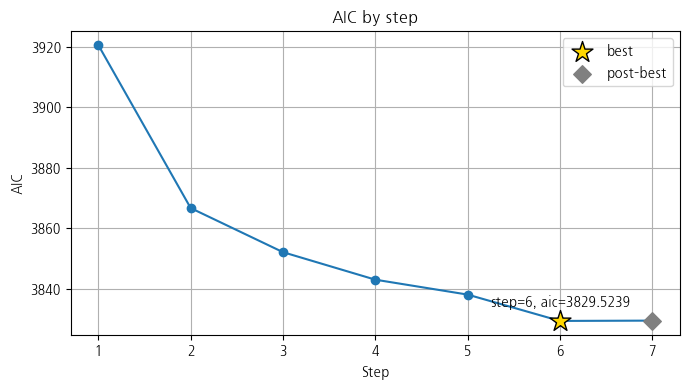

In [4]:
print("선택된 변수:", res["variables"])

sel.plot_history(metric="aic"); plt.show()

In [5]:
sel.get_history_df()

,step,action,selected_units,variables,aic,rmse,r2,adj_r2
0,1,forward-add:bmi,[bmi],[bmi],3920.454920,62.081500,0.365724,0.363917
1,2,forward-add:s5,"[bmi, s5]","[bmi, s5]",3866.732762,57.369997,0.458344,0.455249
2,3,forward-add:bp,"[bmi, s5, bp]","[bmi, bp, s5]",3852.191949,56.041504,0.483139,0.478697
3,4,forward-add:s1,"[bmi, s5, bp, s1]","[bmi, bp, s1, s5]",3843.123110,55.169723,0.499095,0.493337
4,5,forward-add:s2,"[bmi, s5, bp, s1, s2]","[bmi, bp, s1, s2, s5]",3838.205060,54.631759,0.508816,0.501738
5,6,forward-add:sex,"[bmi, s5, bp, s1, s2, sex]","[sex, bmi, bp, s1, s2, s5]",3829.523909,53.811450,0.523456,0.515192
6,7,post-best-add:s4,"[bmi, s5, bp, s1, s2, sex, s4]","[sex, bmi, bp, s1, s2, s4, s5]",3829.627324,53.667086,0.526009,0.516392


In [6]:
res["coef_table"]

,coef,std_err,t_value,p_value,ci_lower,ci_upper,vif
const,153.736544,2.892921,53.142315,1.703887e-168,148.046619,159.426469,NaN
sex,-10.241663,3.141357,-3.260268,1.223667e-03,-16.420221,-4.063105,1.179129
bmi,26.309836,3.586777,7.335231,1.585695e-12,19.255206,33.364466,1.537218
bp,16.948653,3.312962,5.115861,5.186422e-07,10.432574,23.464732,1.311474
s1,-40.632693,8.641130,-4.702243,3.722812e-06,-57.628446,-23.636939,8.922114
s2,28.114579,7.796802,3.605912,3.567981e-04,12.779487,43.449672,7.263731
s5,38.357441,4.437288,8.644344,2.043004e-16,29.629989,47.084893,2.352675


In [7]:
'y = ' + ' + '.join([f"[{row['coef']:.2f}]*"+unit for unit, row in res['coef_table'].iterrows()])

'y = [153.74]*const + [-10.24]*sex + [26.31]*bmi + [16.95]*bp + [-40.63]*s1 + [28.11]*s2 + [38.36]*s5'

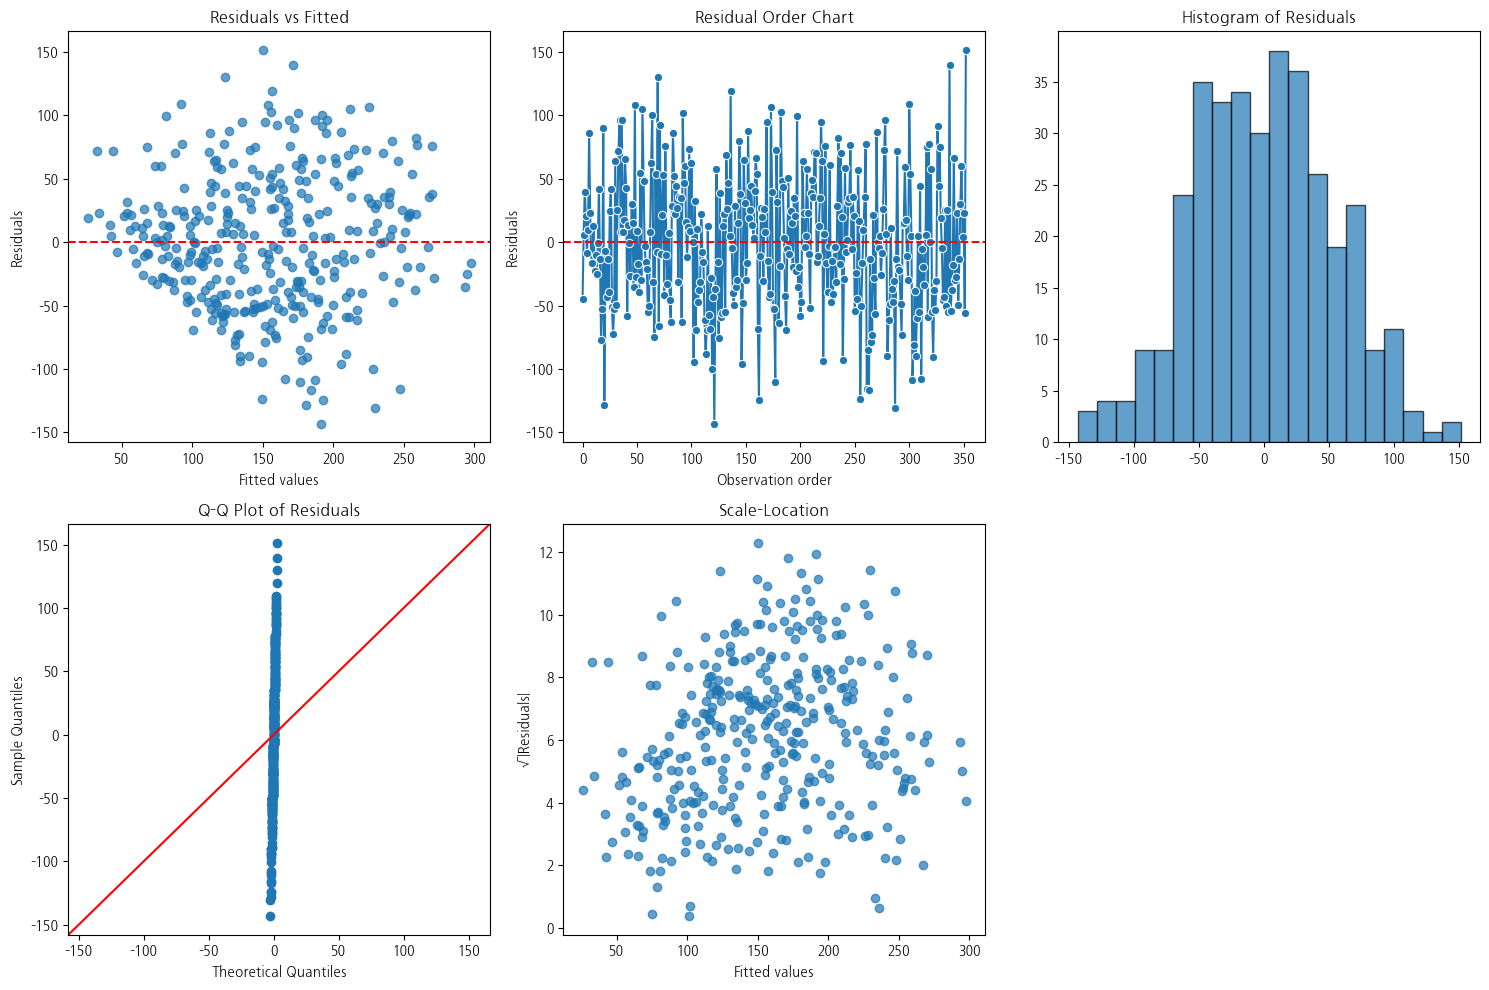

Test RMSE: 53.3506375239674
Test R²: 0.4627767079320303


In [8]:
ResidualAnalyzer(res).plot_residuals(); plt.show()
print("Test RMSE:", mean_squared_error(y_test_enc, y_pred_test, squared=False))
print("Test R²:", r2_score(y_test_enc, y_pred_test))

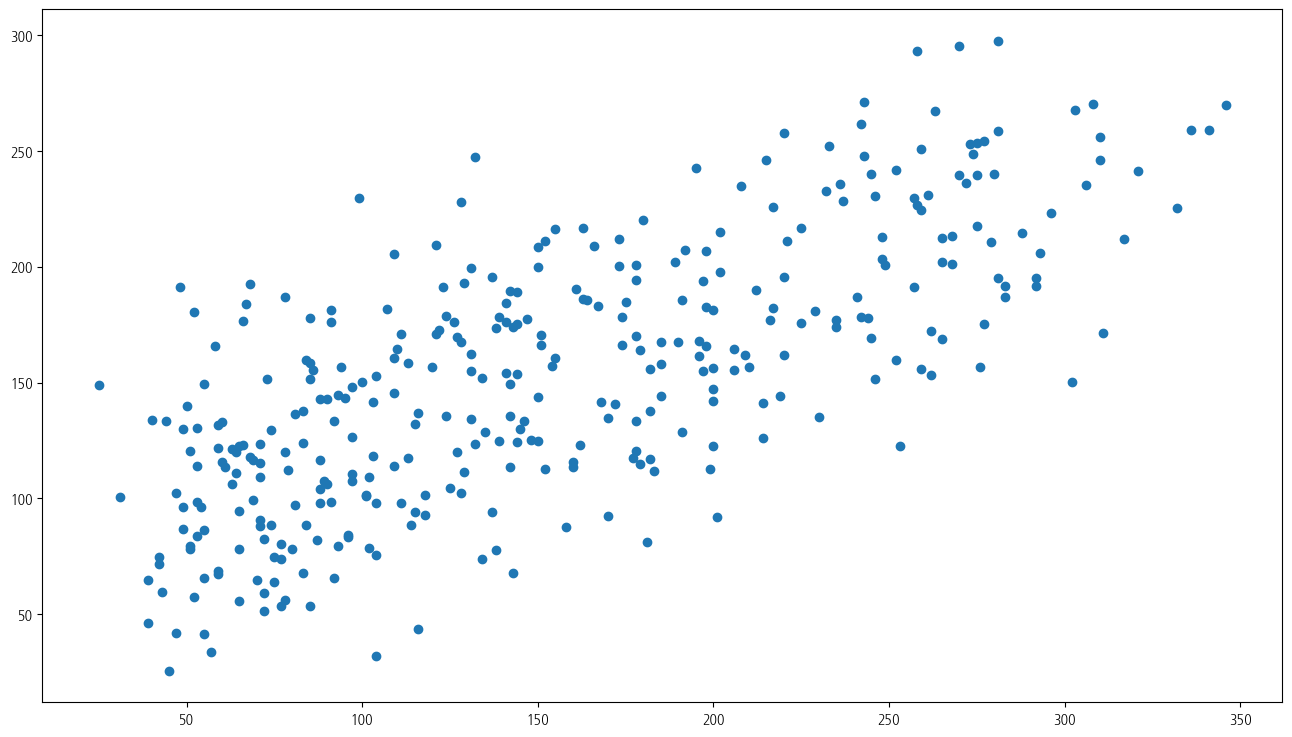

In [18]:
fig, ax = plt.subplots(figsize=(16,9))
ax.scatter(res['predictions']['y'], res['predictions']['y_pred'])
plt.show()

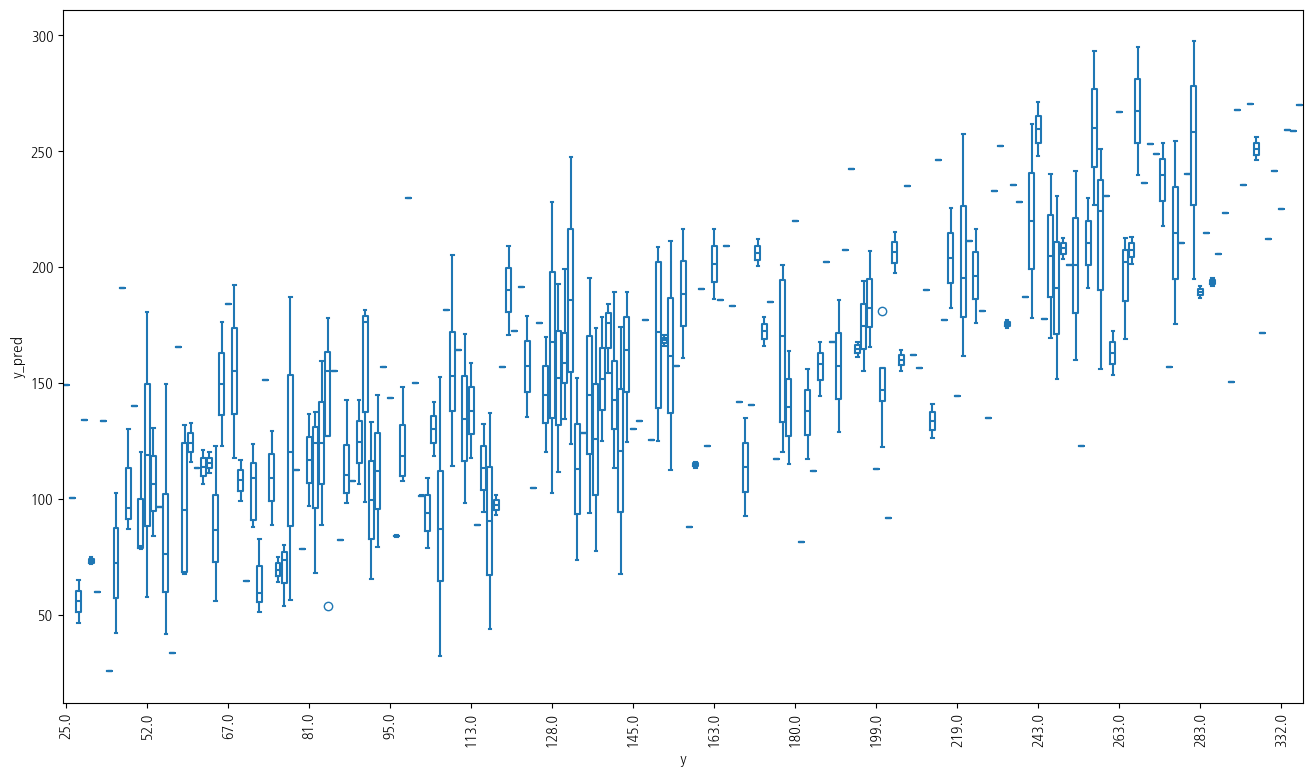

In [17]:
fig, ax = plt.subplots(figsize=(16,9))
sns.boxplot(res['predictions'].sort_values('y'), x='y', y='y_pred', fill=False, ax=ax)

xticks = ax.get_xticks()
if len(xticks) > 15:
    step = len(xticks) // 15
    ax.set_xticks(xticks[::step])
else:
    ax.set_xticks(xticks)
ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
plt.show()

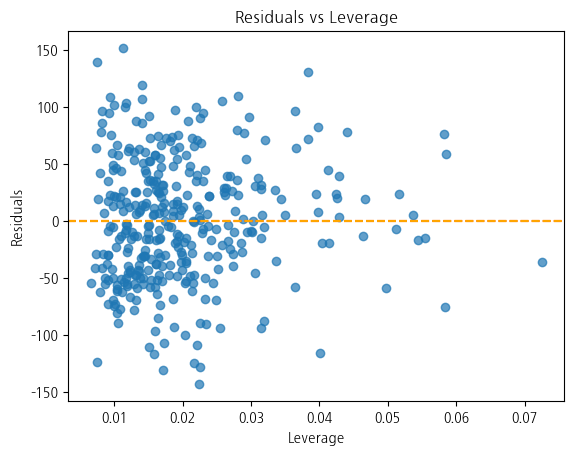

In [19]:
import matplotlib.pyplot as plt
import numpy as np

influence = model.get_influence()
resid = res['predictions']['y'] - res['predictions']['y_pred']
leverage = influence.hat_matrix_diag

fig, ax = plt.subplots()
ax.scatter(leverage, resid, alpha=0.7)
ax.set_xlabel("Leverage")
ax.set_ylabel("Residuals")
ax.set_title("Residuals vs Leverage")
cutoff = 4 / len(res['predictions']['y'])
ax.axhline(0, color="red", linestyle="--")
ax.axhline(np.sqrt(cutoff), color="orange", linestyle="--")
ax.axhline(-np.sqrt(cutoff), color="orange", linestyle="--")

plt.show()

## Case 2: 수치형→이항 (breast_cancer, Backward, MinMaxScaler)

In [24]:
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import accuracy_score, roc_auc_score

data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

prep = Preprocessor(num_cols=X.columns.tolist(), cat_cols=None, scaler="minmax", impute="median")
X_train_proc, y_train_enc = prep.fit_transform(X_train, y_train)
X_test_proc, y_test_enc = prep.transform(X_test, y_test)

sel = VariableSelector(X_train_proc, y_train_enc, method="backward", model_type="auto")
res = sel.select()

X_test_sel = sm.add_constant(X_test_proc[res["variables"]])
model = sel.final_fit_
y_pred_prob = model.predict(X_test_sel)
y_pred_test = (y_pred_prob > 0.5).astype(int)

# 👉 해석 가이드
# - Backward 방식은 모든 변수를 넣고, 불필요한 변수를 제거하면서 최적 모델을 찾습니다.
# - breast_cancer 데이터에서는 유방암 여부(악성=1, 양성=0)를 예측합니다.
# - coef_table의 계수 부호는 특정 변수 증가가 악성 여부를 높이는지/낮추는지 해석 가능합니다.
# - ResidualAnalyzer에서 Deviance Residual이 정규 분포에 가깝게 퍼져있으면 좋은 모델입니다.
# - Accuracy와 AUC가 높게 나오면 분류 성능이 우수합니다.

# 📌 해석 예시 (Case 2)
# - Deviance residuals가 중심에 모여 있으면 로지스틱 모델이 잘 맞음.
# - Residual vs Fitted에서 특정 패턴이 없으면 적합.
# - Accuracy, LogLoss가 균형 있게 나와야 과적합이 아님.

c:\Users\10007166\AppData\Local\anaconda3\envs\auto_eda\Lib\site-packages\statsmodels\base\model.py:595: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  warnings.warn('Inverting hessian failed, no bse or cov_params '
c:\Users\10007166\AppData\Local\anaconda3\envs\auto_eda\Lib\site-packages\statsmodels\base\model.py:595: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  warnings.warn('Inverting hessian failed, no bse or cov_params '
c:\Users\10007166\AppData\Local\anaconda3\envs\auto_eda\Lib\site-packages\statsmodels\base\model.py:595: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  warnings.warn('Inverting hessian failed, no bse or cov_params '
c:\Users\10007166\AppData\Local\anaconda3\envs\auto_eda\Lib\site-packages\statsmodels\base\model.py:595: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  warnings.warn('Inverting hessian failed, no bse or c

선택된 변수: ['mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concave points', 'radius error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst texture', 'worst area', 'worst concavity', 'worst symmetry']


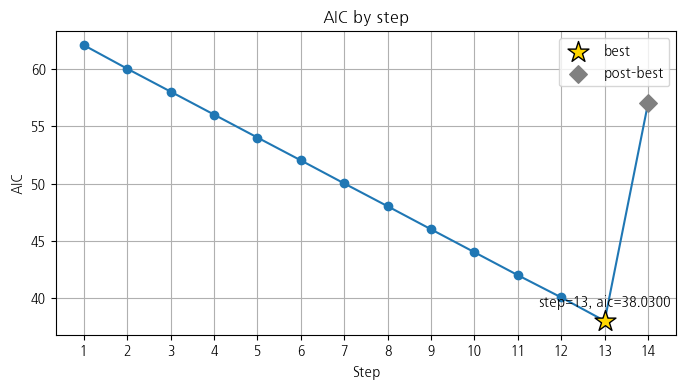

In [25]:
print("선택된 변수:", res["variables"])

sel.plot_history(metric="aic"); plt.show()

In [26]:
sel.get_history_df()

,step,action,selected_units,variables,aic,logloss,accuracy
0,1,start-full,"[mean radius, mean texture, mean perimeter, me...","[mean radius, mean texture, mean perimeter, me...",62.056905,0.000063,1.000000
1,2,backward-drop:mean fractal dimension,"[mean radius, mean texture, mean perimeter, me...","[mean radius, mean texture, mean perimeter, me...",60.005016,0.000006,1.000000
2,3,backward-drop:worst fractal dimension,"[mean radius, mean texture, mean perimeter, me...","[mean radius, mean texture, mean perimeter, me...",58.009034,0.000010,1.000000
3,4,backward-drop:texture error,"[mean radius, mean texture, mean perimeter, me...","[mean radius, mean texture, mean perimeter, me...",56.009157,0.000010,1.000000
4,5,backward-drop:worst perimeter,"[mean radius, mean texture, mean perimeter, me...","[mean radius, mean texture, mean perimeter, me...",54.007943,0.000009,1.000000
5,6,backward-drop:mean symmetry,"[mean radius, mean texture, mean perimeter, me...","[mean radius, mean texture, mean perimeter, me...",52.018696,0.000021,1.000000
6,7,backward-drop:worst radius,"[mean radius, mean texture, mean perimeter, me...","[mean radius, mean texture, mean perimeter, me...",50.008381,0.000009,1.000000
7,8,backward-drop:worst compactness,"[mean radius, mean texture, mean perimeter, me...","[mean radius, mean texture, mean perimeter, me...",48.020664,0.000023,1.000000
8,9,backward-drop:mean concavity,"[mean radius, mean texture, mean perimeter, me...","[mean radius, mean texture, mean perimeter, me...",46.012655,0.000014,1.000000
9,10,backward-drop:worst smoothness,"[mean radius, mean texture, mean perimeter, me...","[mean radius, mean texture, mean perimeter, me...",44.014987,0.000016,1.000000


In [27]:
res["coef_table"]

,coef,std_err,z,P>|z|,ci_lower,ci_upper,vif
const,6.824470e+05,NaN,NaN,NaN,NaN,NaN,NaN
mean texture,-4.125560e+05,NaN,NaN,NaN,NaN,NaN,48.002333
mean perimeter,4.189962e+06,NaN,NaN,NaN,NaN,NaN,311.972660
mean area,-3.429117e+06,NaN,NaN,NaN,NaN,NaN,358.186157
mean smoothness,-3.186633e+05,NaN,NaN,NaN,NaN,NaN,25.294867
mean compactness,1.315386e+06,NaN,NaN,NaN,NaN,NaN,51.841187
mean concave points,-1.385508e+06,NaN,NaN,NaN,NaN,NaN,37.654444
radius error,-2.370769e+06,NaN,NaN,NaN,NaN,NaN,38.223133
area error,3.549018e+06,NaN,NaN,NaN,NaN,NaN,31.972162
smoothness error,-1.140521e+05,NaN,NaN,NaN,NaN,NaN,7.960875


In [28]:
'y = ' + ' + '.join([f"[{row['coef']:.2f}]*"+unit for unit, row in res['coef_table'].iterrows()])

'y = [682447.01]*const + [-412555.96]*mean texture + [4189961.74]*mean perimeter + [-3429116.71]*mean area + [-318663.29]*mean smoothness + [1315386.42]*mean compactness + [-1385507.77]*mean concave points + [-2370769.40]*radius error + [3549017.75]*area error + [-114052.09]*smoothness error + [-569154.79]*compactness error + [2252571.57]*concavity error + [-976367.85]*concave points error + [286133.26]*symmetry error + [858423.76]*fractal dimension error + [-233296.49]*worst texture + [-3579938.37]*worst area + [-1577228.59]*worst concavity + [-343689.87]*worst symmetry'

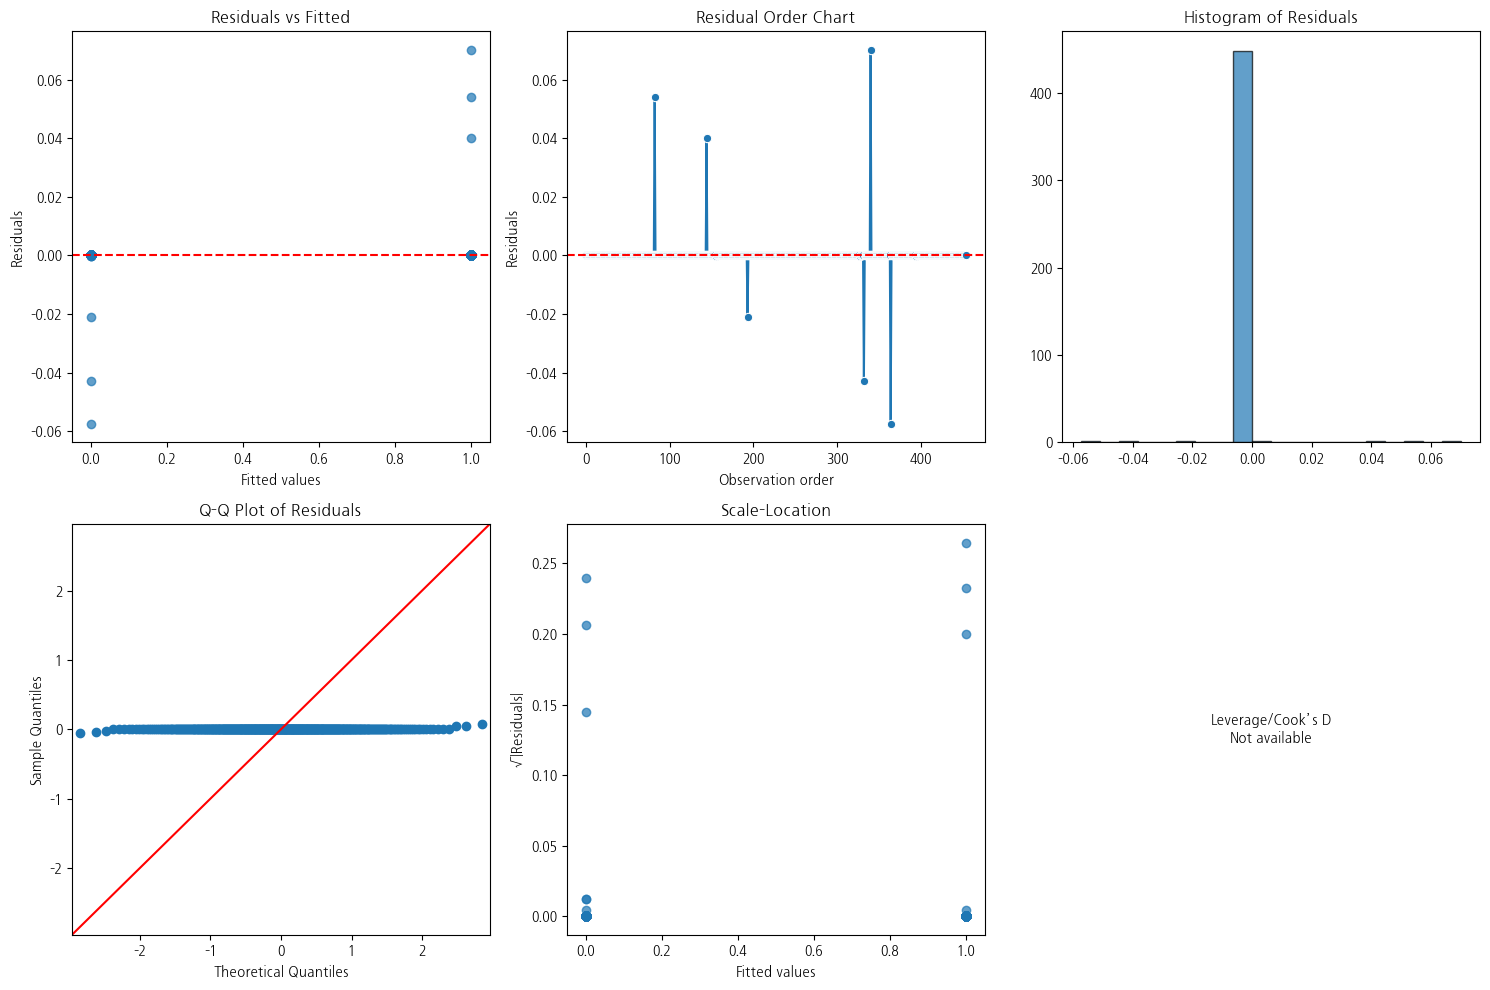

Test Accuracy: 0.9385964912280702
Test AUC: 0.9415329184408779


In [29]:
ResidualAnalyzer(res).plot_residuals(); plt.show()
print("Test Accuracy:", accuracy_score(y_test_enc, y_pred_test))
print("Test AUC:", roc_auc_score(y_test_enc, y_pred_prob))

## Case 3: 수치형→3범주 (wine, Stepwise, RobustScaler)

In [5]:
from sklearn.datasets import load_wine

data = load_wine(as_frame=True)
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

prep = Preprocessor(num_cols=X.columns.tolist(), cat_cols=None, scaler="robust", impute="median")
X_train_proc, y_train_enc = prep.fit_transform(X_train, y_train)
X_test_proc, y_test_enc = prep.transform(X_test, y_test)

sel = VariableSelector(X_train_proc, y_train_enc, method="stepwise", model_type="auto")
res = sel.select()

# 주의: 다항 로지스틱 회귀는 sklearn 객체로 학습되므로 테스트셋 predict 로직은 별도 구현 필요
X_test_sel = X_test_proc[res["variables"]]
model = res['model']
y_pred_test = model.predict(X_test_sel)

from sklearn.preprocessing import label_binarize
classes = list(y.unique())
y_pred_label_bin = label_binarize(y_test_enc, classes=classes)
y_pred_test_bin = label_binarize(y_pred_test, classes=classes)

# 👉 해석 가이드
# - Stepwise 방식은 Forward와 Backward를 결합하여 변수를 추가/제거합니다.
# - wine 데이터에서는 와인의 종류(3범주)를 분류합니다.
# - coef_table은 클래스별 회귀계수를 보여주며, 어떤 변수들이 특정 와인 클래스에 영향을 주는지 확인할 수 있습니다.
# - ResidualAnalyzer에서 클래스별 잔차 분포를 확인하고, 이상치가 치우쳐 있지 않은지 점검합니다.
# - Accuracy가 높으면 모델이 와인 종류를 잘 구분하고 있다는 의미입니다.

# 📌 해석 예시 (Case 3)
# - Multinomial residuals가 큰 편차 없이 퍼져 있으면 분류 모델 적합.
# - Q-Q plot에서 꼬리 부분 벗어나면 일부 클래스 구분이 어렵다는 신호.
# - Accuracy가 높고 LogLoss 낮으면 모델 설명력이 충분.

In [6]:
y_pred_label_bin

array([[1, 0, 0],
       [1, 0, 0],
       [0, 0, 1],
       [1, 0, 0],
       [0, 1, 0],
       [1, 0, 0],
       [0, 1, 0],
       [0, 0, 1],
       [0, 1, 0],
       [0, 0, 1],
       [1, 0, 0],
       [0, 0, 1],
       [1, 0, 0],
       [0, 1, 0],
       [1, 0, 0],
       [0, 1, 0],
       [0, 1, 0],
       [0, 1, 0],
       [1, 0, 0],
       [0, 1, 0],
       [1, 0, 0],
       [0, 1, 0],
       [0, 1, 0],
       [0, 0, 1],
       [0, 0, 1],
       [0, 0, 1],
       [0, 1, 0],
       [0, 1, 0],
       [0, 1, 0],
       [1, 0, 0],
       [1, 0, 0],
       [0, 1, 0],
       [0, 0, 1],
       [1, 0, 0],
       [1, 0, 0],
       [1, 0, 0]])

In [7]:
y_pred_test_bin

array([[1, 0, 0],
       [1, 0, 0],
       [0, 0, 1],
       [1, 0, 0],
       [0, 1, 0],
       [1, 0, 0],
       [0, 1, 0],
       [0, 0, 1],
       [0, 1, 0],
       [0, 0, 1],
       [1, 0, 0],
       [0, 0, 1],
       [1, 0, 0],
       [0, 1, 0],
       [1, 0, 0],
       [0, 1, 0],
       [0, 1, 0],
       [0, 1, 0],
       [1, 0, 0],
       [0, 1, 0],
       [1, 0, 0],
       [0, 1, 0],
       [0, 1, 0],
       [0, 0, 1],
       [0, 0, 1],
       [0, 0, 1],
       [0, 1, 0],
       [0, 1, 0],
       [0, 1, 0],
       [1, 0, 0],
       [1, 0, 0],
       [0, 1, 0],
       [0, 0, 1],
       [1, 0, 0],
       [1, 0, 0],
       [1, 0, 0]])

In [10]:
res['model']

KeyError: 'model'

In [5]:
print("선택된 변수:", res["variables"])
sel.plot_history(metric="aic"); plt.show()

선택된 변수: ['alcohol', 'flavanoids', 'color_intensity', 'hue', 'proline']


AttributeError: 'VariableSelector' object has no attribute 'plot_history'

In [6]:
sel.get_history_df()

,step,action,variables,aic,best
0,1,forward-add:flavanoids,['flavanoids'],162.347999,
1,2,forward-add:alcohol,"['alcohol', 'flavanoids']",94.153388,
2,3,forward-add:color_intensity,"['alcohol', 'flavanoids', 'color_intensity']",72.177089,
3,4,forward-add:proline,"['alcohol', 'flavanoids', 'color_intensity', '...",56.964916,
4,5,forward-add:hue,"['alcohol', 'flavanoids', 'color_intensity', '...",54.080163,☆
5,6,stop,"['alcohol', 'ash', 'flavanoids', 'color_intens...",54.592372,


In [7]:
res["coef_table"]

,const,alcohol,flavanoids,color_intensity,hue,proline
class=0,-0.021234,1.120110,1.443300,0.293690,0.191965,1.644452
class=1,0.618493,-1.365514,0.472377,-1.473092,1.132940,-1.424811
class=2,-0.597259,0.245403,-1.915677,1.179402,-1.324905,-0.219641


In [8]:
ResidualAnalyzer(res).plot_residuals(); plt.show()
print("Test Accuracy:", accuracy_score(y_test_enc, y_pred_test))
print("Test AUC:", roc_auc_score(y_pred_label_bin, y_pred_test_bin, average='macro'))

TypeError: ResidualAnalyzer.__init__() missing 4 required positional arguments: 'y_pred', 'model_type', 'model', and 'output_dir'

## Case 4: 혼합→수치형 (tips, Forward, 스케일러 없음)

In [52]:
import seaborn as sns
from sklearn.metrics import mean_squared_error, r2_score

tips = sns.load_dataset("tips")
X = tips[["total_bill","size","sex","smoker","day","time"]]
y = tips["tip"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

prep = Preprocessor(num_cols=["total_bill","size"], cat_cols=["sex","smoker","day","time"], scaler=None, impute="remove")
X_train_proc, y_train_enc = prep.fit_transform(X_train, y_train)
X_test_proc, y_test_enc = prep.transform(X_test, y_test)

sel = VariableSelector(X_train_proc, y_train_enc, method="forward", model_type="auto", group_map=prep.group_map)
res = sel.select()

X_test_sel = sm.add_constant(X_test_proc[res["variables"]])
model = sel.final_fit_
y_pred_test = model.predict(X_test_sel)

# 👉 해석 가이드
# - 독립변수: total_bill, size (수치) + sex, smoker, day, time (범주)
# - Forward 방식으로 tip 예측에 유의미한 변수만 선택됩니다.
# - coef_table을 통해 '흡연 여부(smoker)'나 '요일(day)' 같은 범주형 변수가 팁에 어떤 영향을 주는지 확인할 수 있습니다.
# - ResidualAnalyzer에서 잔차가 랜덤하게 분포하면 모델이 선형 회귀 가정을 잘 충족한 것입니다.
# - Test RMSE와 R²를 통해 팁 예측력이 어느 정도인지 판단할 수 있습니다.

# 📌 해석 예시 (Case 4)
# - Residual vs Fitted에서 특정 요일/성별 그룹에 따라 패턴이 보이면 범주형 효과가 있음.
# - Histogram/Q-Q에서 정규성 위반 시 범주형 교호작용 추가 고려 가능.

In [54]:
y_train_enc

228    2.72
208    2.03
96     4.00
167    4.50
84     2.03
       ... 
106    4.06
14     3.02
92     1.00
179    3.55
102    2.50
Name: tip, Length: 195, dtype: float64

선택된 변수: ['total_bill', 'size']


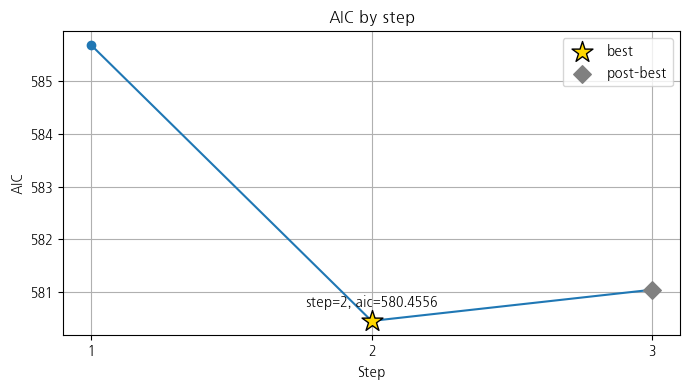

In [36]:
print("선택된 변수:", res["variables"])
sel.plot_history(metric="aic"); plt.show()

In [37]:
sel.get_history_df()

,step,action,selected_units,variables,aic,rmse,r2,adj_r2
0,1,forward-add:total_bill,[total_bill],[total_bill],585.678116,1.075240,0.430951,0.428003
1,2,forward-add:size,"[total_bill, size]","[total_bill, size]",580.455607,1.055511,0.451642,0.445930
2,3,post-best-add:smoker,"[total_bill, size, smoker]","[total_bill, size, smoker_Yes]",581.046343,1.051703,0.455591,0.447040


In [38]:
res["coef_table"]

,coef,std_err,t_value,p_value,ci_lower,ci_upper,vif
const,0.568137,0.233233,2.435917,1.576686e-02,0.108108,1.028166,NaN
total_bill,0.090881,0.010561,8.605704,2.697553e-15,0.070052,0.111711,8.48458
size,0.265018,0.098461,2.691604,7.738751e-03,0.070814,0.459221,8.48458


In [39]:
'y = ' + ' + '.join([f"[{row['coef']:.2f}]*"+unit for unit, row in res['coef_table'].iterrows()])

'y = [0.57]*const + [0.09]*total_bill + [0.27]*size'

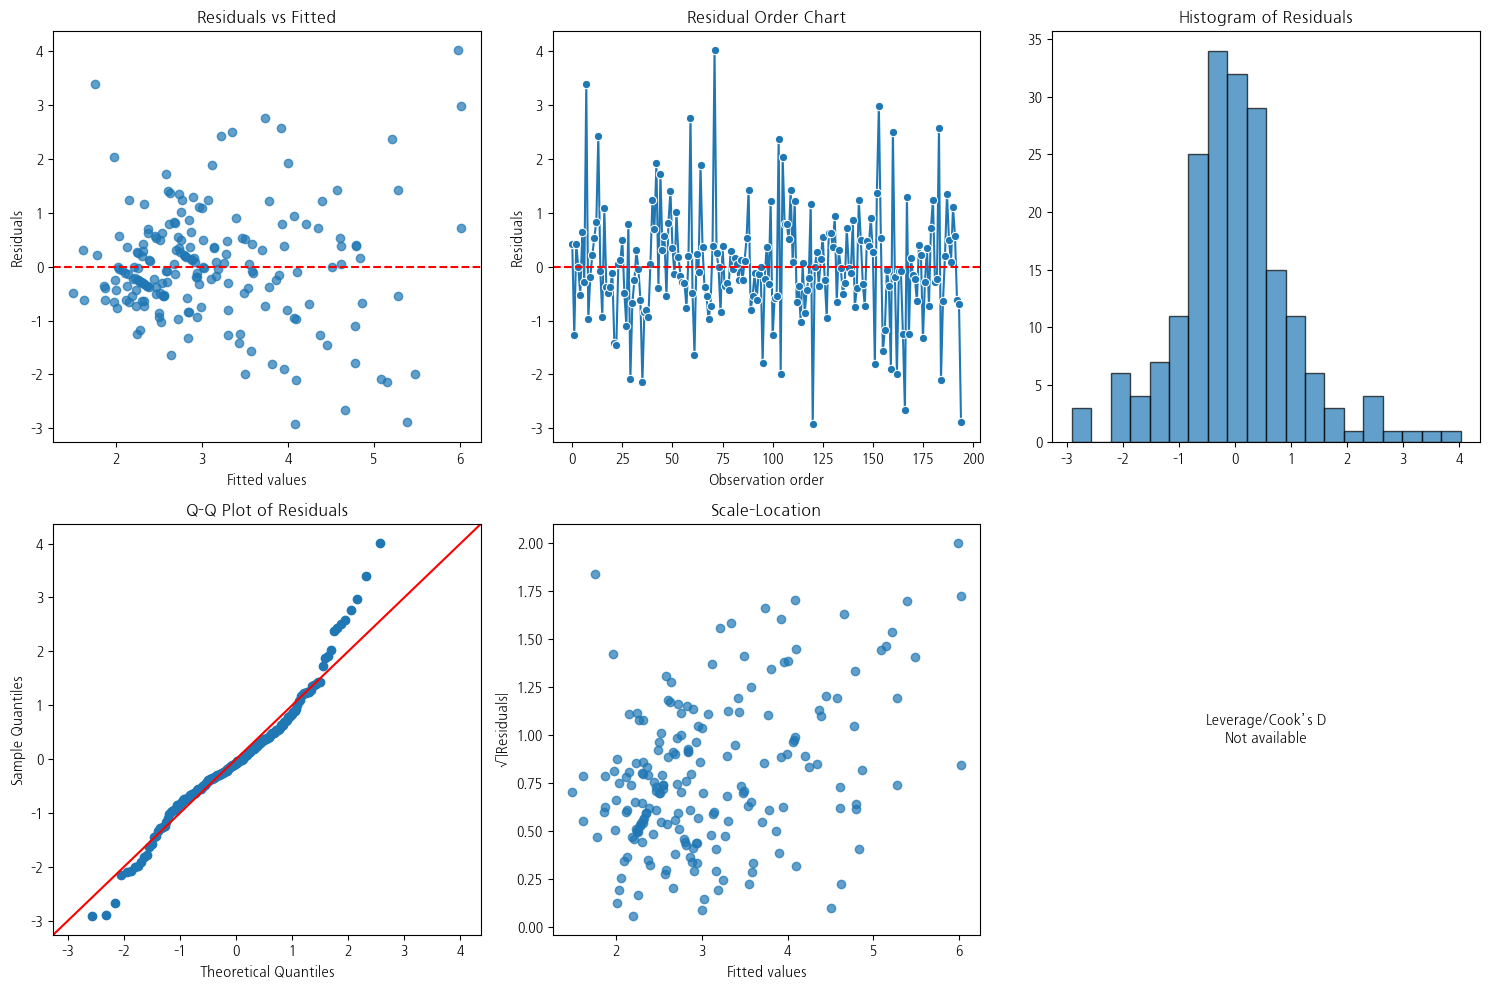

Test RMSE: 0.8053568271607008
Test R²: 0.48110840979894975


In [40]:
ResidualAnalyzer(res).plot_residuals(); plt.show()
print("Test RMSE:", mean_squared_error(y_test_enc, y_pred_test, squared=False))
print("Test R²:", r2_score(y_test_enc, y_pred_test))

## Case 5: 혼합→이항 (titanic, Backward, StandardScaler)

In [60]:
titanic = sns.load_dataset("titanic").dropna(subset=["age","sex","class","embarked","survived"])
X = titanic[["age","fare","sex","class","embarked"]]
y = titanic["survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

prep = Preprocessor(num_cols=["age","fare"], cat_cols=["sex","class","embarked"], scaler="standard", impute="remove")
X_train_proc, y_train_enc = prep.fit_transform(X_train, y_train)
X_test_proc, y_test_enc = prep.transform(X_test, y_test)

sel = VariableSelector(X_train_proc, y_train_enc, method="backward", model_type="auto", group_map=prep.group_map)
res = sel.select()

X_test_sel = sm.add_constant(X_test_proc[res["variables"]])
model = sel.final_fit_
y_pred_prob = model.predict(X_test_sel)
y_pred_test = (y_pred_prob > 0.5).astype(int)

# 👉 해석 가이드
# - 독립변수: age, fare (수치형) + sex, class, embarked (범주형)
# - 종속변수: survived (0=사망, 1=생존)
# - Backward 선택법으로 생존에 불필요한 변수 제거 후 최적 모델을 찾습니다.
# - coef_table에서 성별(sex), 선실 등급(class) 등이 생존 확률에 큰 영향을 미치는지 확인할 수 있습니다.
# - ResidualAnalyzer에서 잔차가 크게 치우치지 않으면 모델이 적합합니다.
# - Accuracy와 AUC로 모델의 분류 성능을 평가합니다.

# 📌 해석 예시 (Case 5)
# - Deviance residuals가 특정 클래스(예: 여성, 1등석)에서 집중되면
#   해당 요인이 종속변수에 큰 영향.
# - Accuracy 높고 LogLoss 낮으면 잘 맞는 모델.

선택된 변수: ['age', 'sex_male', 'class_Second', 'class_Third']


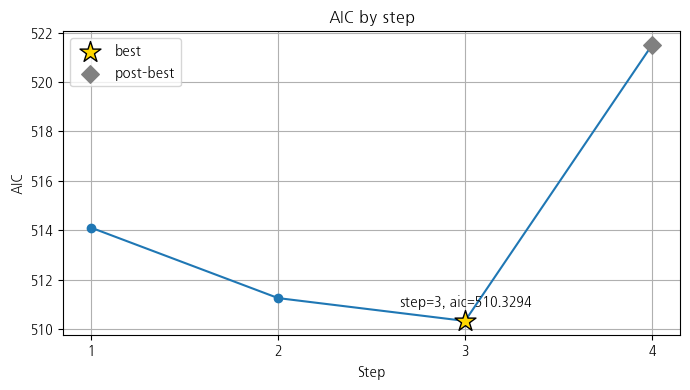

In [61]:
print("선택된 변수:", res["variables"])
sel.plot_history(metric="aic"); plt.show()

In [62]:
sel.get_history_df()

,step,action,selected_units,variables,aic,logloss,accuracy
0,1,start-full,"[sex, class, embarked, age, fare]","[age, fare, sex_male, class_Second, class_Thir...",514.103044,0.437700,0.794376
1,2,backward-drop:embarked,"[sex, class, age, fare]","[age, fare, sex_male, class_Second, class_Third]",511.253825,0.438712,0.794376
2,3,backward-drop:fare,"[sex, class, age]","[age, sex_male, class_Second, class_Third]",510.329407,0.439657,0.789104
3,4,post-best-drop:age,"[sex, class]","[sex_male, class_Second, class_Third]",521.493308,0.451224,0.787346


In [63]:
res["coef_table"]

,coef,std_err,z,P>|z|,ci_lower,ci_upper,vif
const,2.735789,0.298311,9.170946,4.688881e-20,2.151112,3.320467,NaN
age,-0.438602,0.124317,-3.528097,4.185589e-04,-0.682259,-0.194945,1.180875
sex_male,-2.627979,0.240226,-10.939626,7.450682e-28,-3.098813,-2.157145,2.325658
class_Second,-1.365763,0.312890,-4.364987,1.271302e-05,-1.979017,-0.752509,1.282779
class_Third,-2.699380,0.323749,-8.337888,7.562897e-17,-3.333916,-2.064844,2.125302


In [64]:
'y = ' + ' + '.join([f"[{row['coef']:.2f}]*"+unit for unit, row in res['coef_table'].iterrows()])

'y = [2.74]*const + [-0.44]*age + [-2.63]*sex_male + [-1.37]*class_Second + [-2.70]*class_Third'

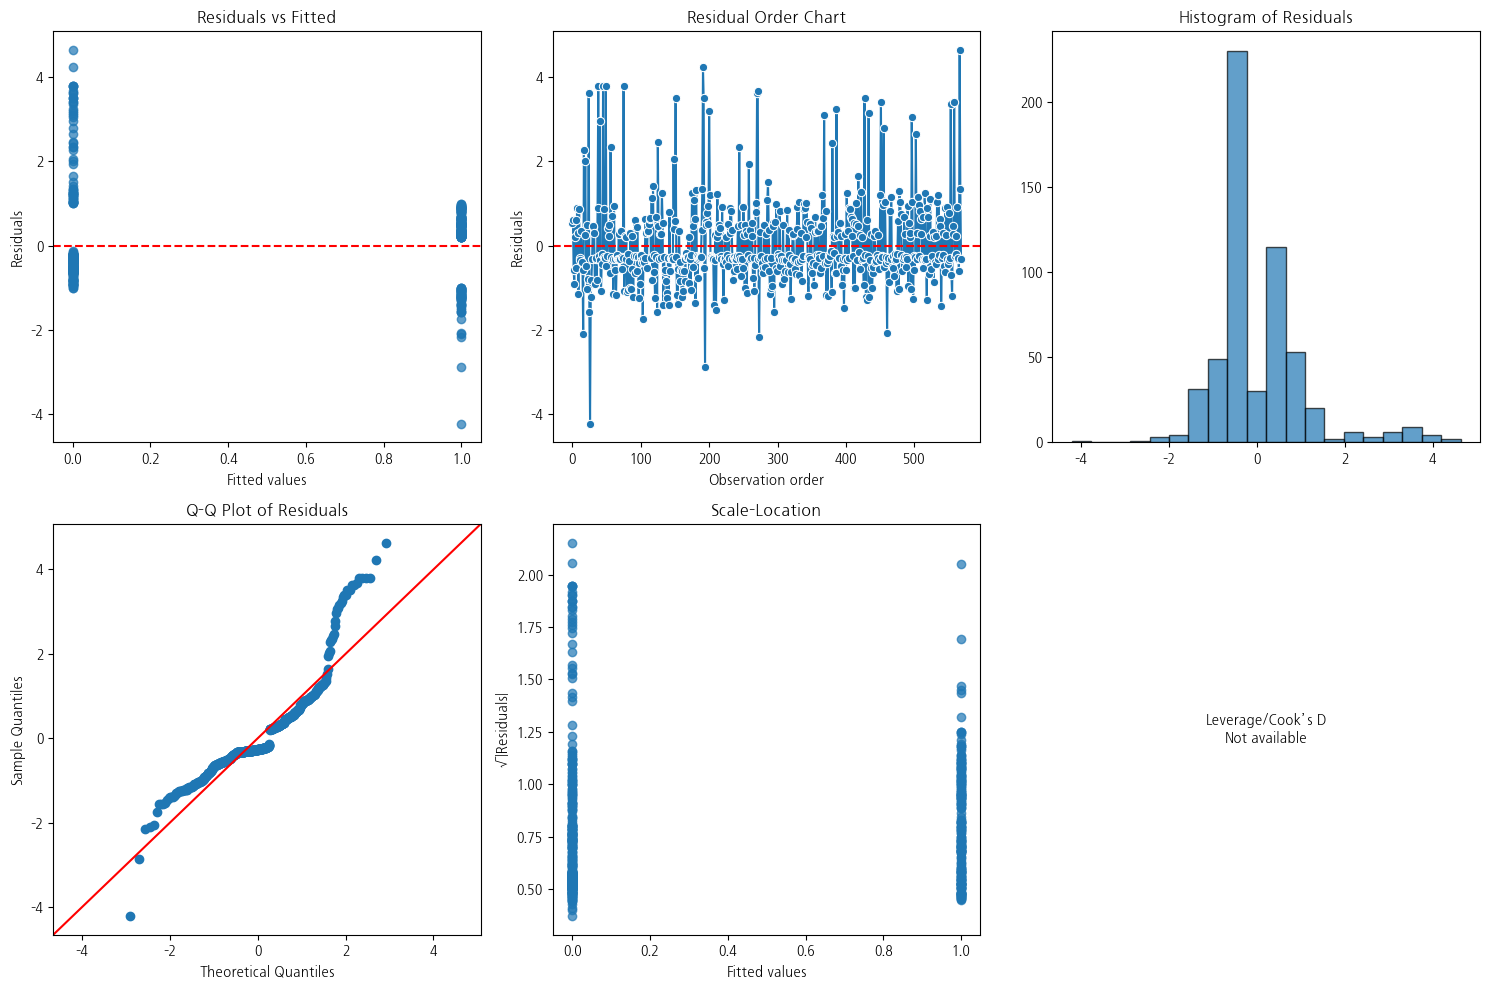

Test Accuracy: 0.7902097902097902
Test AUC: 0.820138888888889


In [65]:
ResidualAnalyzer(res).plot_residuals(); plt.show()
print("Test Accuracy:", accuracy_score(y_test_enc, y_pred_test))
print("Test AUC:", roc_auc_score(y_test_enc, y_pred_prob))

## Case 6: 혼합→3범주 (iris+가공, Stepwise, MinMaxScaler)

In [47]:
iris = sns.load_dataset("iris")
iris["petal_size_cat"] = pd.cut(iris["petal_length"], bins=3, labels=["short","medium","long"])

X = iris[["sepal_length","sepal_width","petal_width","petal_size_cat"]]
y = iris["species"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

prep = Preprocessor(num_cols=["sepal_length","sepal_width","petal_width"], cat_cols=["petal_size_cat"], scaler="minmax", impute="remove")
X_train_proc, y_train_enc = prep.fit_transform(X_train, y_train)
X_test_proc, y_test_enc = prep.transform(X_test, y_test)

sel = VariableSelector(X_train_proc, y_train_enc, method="stepwise", model_type="auto", group_map=prep.group_map)
res = sel.select()

# multilogit: y_pred 해석 시 prep.inverse_transform_y() 로 다시 문자 라벨 복원 가능
X_test_sel = X_test_proc[res["variables"]]
model = sel.final_fit_
y_pred_prob = model.predict(X_test_sel)
y_pred_label = prep.inverse_transform_y(y_test_enc)
y_pred_test = prep.inverse_transform_y(y_pred_prob)

from sklearn.preprocessing import label_binarize
classes = list(iris["species"].unique())

y_pred_label_bin = label_binarize(y_pred_label, classes=classes)
y_pred_test_bin = label_binarize(y_pred_test, classes=classes)

# 👉 해석 가이드
# - 독립변수: sepal_length, sepal_width, petal_width (수치형) + petal_size_cat (범주형)
# - 종속변수: species (setosa, versicolor, virginica)
# - Stepwise 방식으로 다항 로지스틱 회귀를 수행합니다.
# - coef_table에서 각 품종별로 어떤 특성이 차별화 요소인지 파악할 수 있습니다.
# - ResidualAnalyzer 플롯에서 Deviance Residual이 고르게 퍼져 있으면 좋은 적합도입니다.
# - Accuracy가 높으면 모델이 붓꽃 품종을 잘 분류하고 있다는 의미입니다.

# 📌 해석 예시 (Case 6)
# - Multinomial residuals에서 특정 종(setosa 등)에 잔차가 작으면 해당 클래스는 잘 분리.
# - Q-Q에서 꼬리 벗어나면 일부 종 분리가 약함.
# - Accuracy와 LogLoss로 전반적 적합도 확인.

선택된 변수: ['petal_width', 'petal_size_cat_medium', 'petal_size_cat_short']


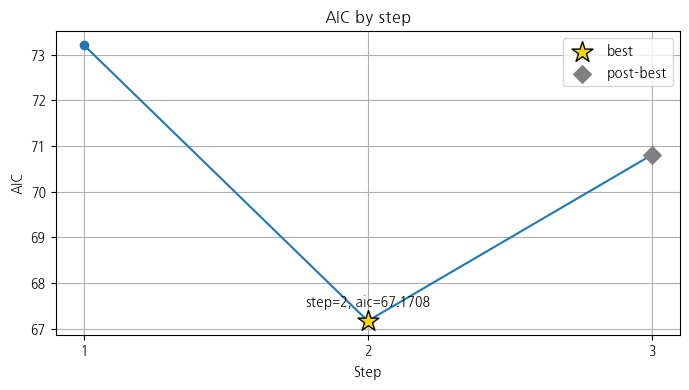

In [48]:
print("선택된 변수:", res["variables"])
sel.plot_history(metric="aic"); plt.show()

In [49]:
sel.get_history_df()

,step,action,selected_units,variables,aic,logloss,accuracy
0,1,forward-add:petal_size_cat,[petal_size_cat],"[petal_size_cat_medium, petal_size_cat_short]",73.208679,0.255036,0.941667
1,2,forward-add:petal_width,"[petal_size_cat, petal_width]","[petal_width, petal_size_cat_medium, petal_siz...",67.170769,0.213212,0.941667
2,3,post-best-add:sepal_length,"[petal_size_cat, petal_width, sepal_length]","[sepal_length, petal_width, petal_size_cat_med...",70.802537,0.211677,0.941667


In [50]:
res["coef_table"]

,const,petal_width,petal_size_cat_medium,petal_size_cat_short
class=0,-0.107472,-1.469827,-0.952625,2.474969
class=1,0.005555,-0.707575,2.187794,-1.159239
class=2,0.101917,2.177402,-1.235168,-1.315730


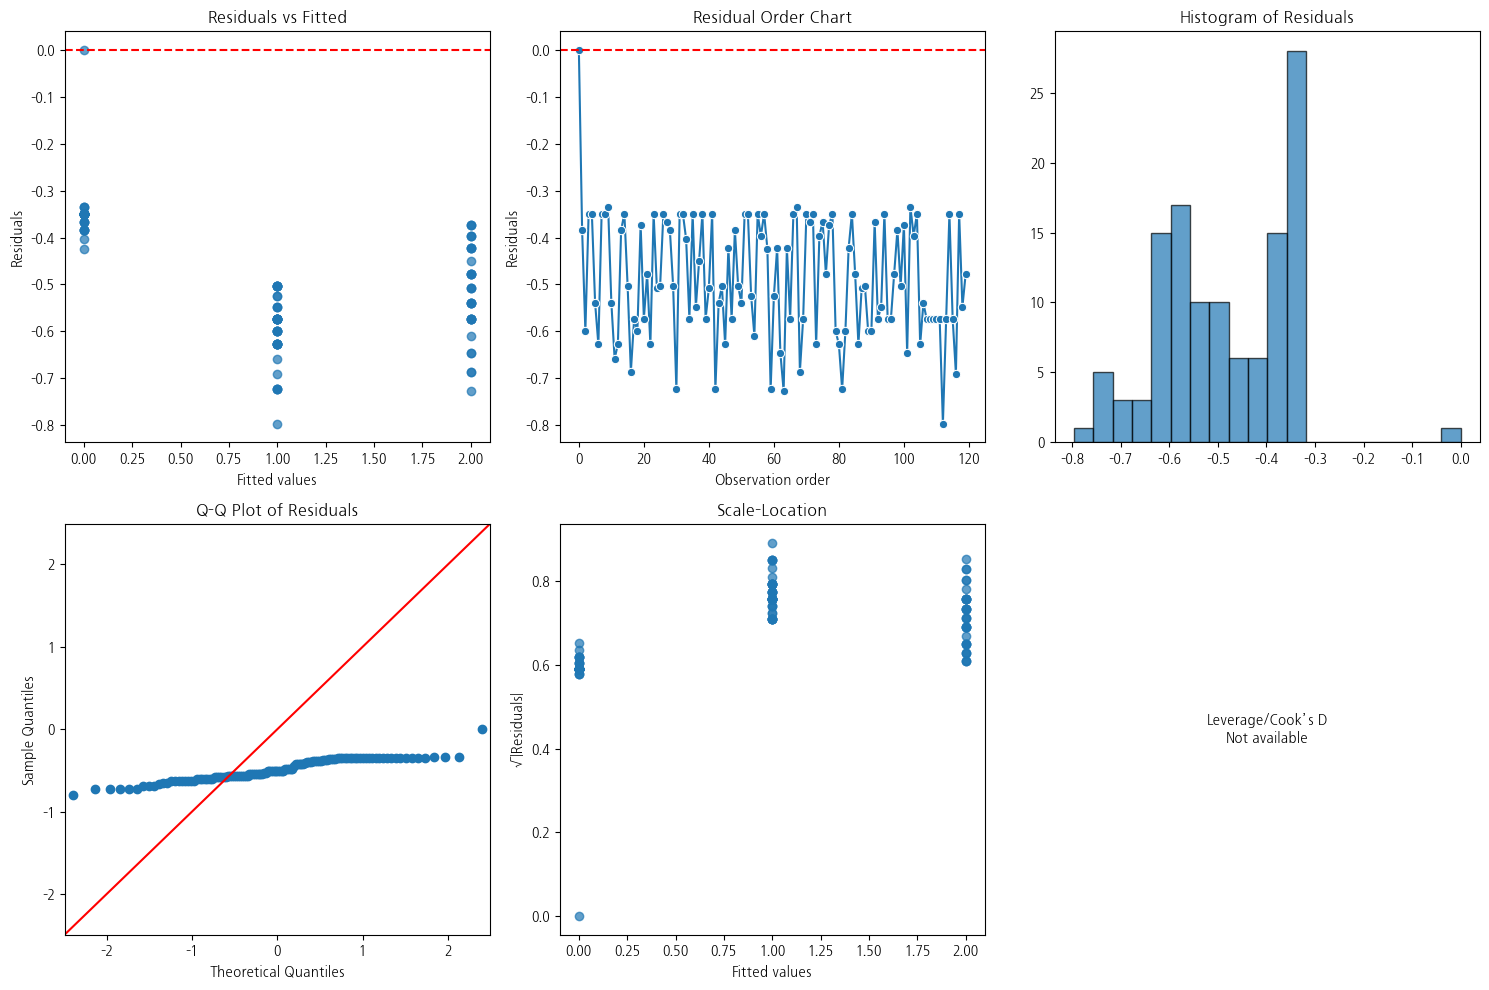

Test Accuracy: 0.9666666666666667
Test AUC: 0.976911976911977


In [51]:
ResidualAnalyzer(res).plot_residuals(); plt.show()
print("Test Accuracy:", accuracy_score(y_pred_label, y_pred_test))
print("Test AUC:", roc_auc_score(y_pred_label_bin, y_pred_test_bin, average='macro'))